In [ ]:
# It contains:

# 150 flowers
# 4 features for each flower
# 3 classes of flowers

# The four features are:

# Sepal length
# Sepal width
# Petal length
# Petal width

In [4]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target

print(X.shape)
print(y.shape)

(150, 4)
(150,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
import math

def euclidean_distance(a, b):
    total = 0
    for i in range(len(a)):
        total += (a[i] - b[i]) ** 2
    return math.sqrt(total)

In [7]:
def manhattan_distance(a, b):
    total = 0
    for i in range(len(a)):
        total += abs(a[i] - b[i])
    return total

In [8]:
def cosine_distance(a, b):
    dot_product = 0
    magnitude_a = 0
    magnitude_b = 0

    for i in range(len(a)):
        dot_product += a[i] * b[i]
        magnitude_a += a[i] ** 2
        magnitude_b += b[i] ** 2

    magnitude_a = math.sqrt(magnitude_a)
    magnitude_b = math.sqrt(magnitude_b)

    # Avoid division by zero
    if magnitude_a == 0 or magnitude_b == 0:
        return 0

    cosine_similarity = dot_product / (magnitude_a * magnitude_b)

    return 1 - cosine_similarity

In [9]:
def knn_predict(X_train, y_train, X_test, k, distance_function):

    predictions = []

    for test_point in X_test:

        distances = []

        # Calculate distance from test point to every training point
        for i in range(len(X_train)):

            distance = distance_function(
                test_point,
                X_train[i]
            )

            distances.append((distance, y_train[i]))

        # Sort by distance
        distances.sort(key=lambda x: x[0])

        # Take the k nearest neighbors
        nearest_neighbors = distances[:k]

        # Get their labels
        labels = []

        for distance, label in nearest_neighbors:
            labels.append(label)

        # Majority voting
        prediction = max(set(labels), key=labels.count)

        predictions.append(prediction)

    return predictions

In [10]:
y_pred_euclidean = knn_predict(
    X_train,
    y_train,
    X_test,
    5,
    euclidean_distance
)

y_pred_manhattan = knn_predict(
    X_train,
    y_train,
    X_test,
    5,
    manhattan_distance
)

y_pred_cosine = knn_predict(
    X_train,
    y_train,
    X_test,
    5,
    cosine_distance
)

In [11]:
print(y_pred_euclidean)
print(y_pred_manhattan)
print(y_pred_cosine)

[np.int64(0), np.int64(2), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(2), np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(2), np.int64(0), np.int64(2), np.int64(1), np.int64(2), np.int64(2), np.int64(1), np.int64(1), np.int64(0), np.int64(2), np.int64(0)]
[np.int64(0), np.int64(2), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(2), np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(2), np.int64(1), np.int64(2), np.int64(2), np.int64(1), np.int64(1), np.int64(0), np.int64(2), np.int64(0)]
[np.int64(0), np.int64(2), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(2), np.int64(1), np.int64(2), np.int64(2), np.int64(2), np.int64(1), np.int64(0), np.int64(0), np.int64(

In [12]:
from sklearn.metrics import accuracy_score

accuracy_euclidean = accuracy_score(y_test, y_pred_euclidean)
accuracy_manhattan = accuracy_score(y_test, y_pred_manhattan)
accuracy_cosine = accuracy_score(y_test, y_pred_cosine)

print("Euclidean Accuracy:", accuracy_euclidean)
print("Manhattan Accuracy:", accuracy_manhattan)
print("Cosine Accuracy:", accuracy_cosine)

Euclidean Accuracy: 1.0
Manhattan Accuracy: 0.9666666666666667
Cosine Accuracy: 1.0


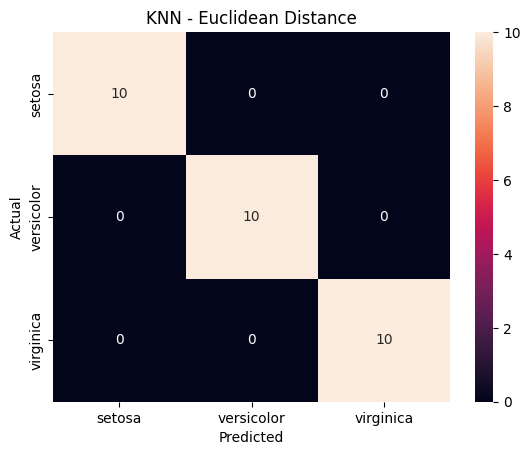

In [13]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_euclidean = confusion_matrix(y_test, y_pred_euclidean)

sns.heatmap(
    cm_euclidean,
    annot=True,
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN - Euclidean Distance")
plt.show()

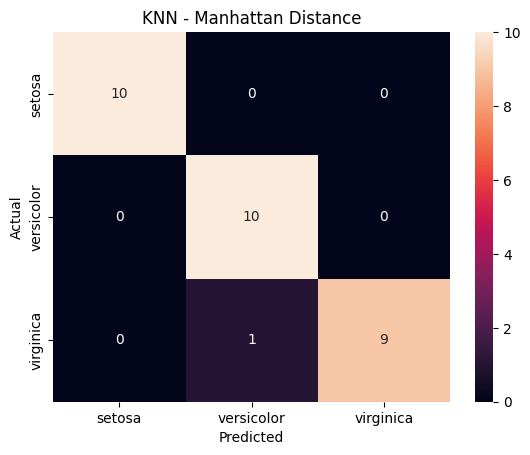

In [14]:
cm_manhattan = confusion_matrix(y_test, y_pred_manhattan)

sns.heatmap(
    cm_manhattan,
    annot=True,
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN - Manhattan Distance")
plt.show()

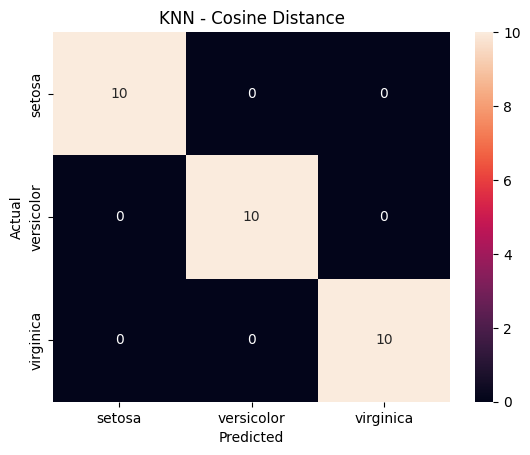

In [15]:
cm_cosine = confusion_matrix(y_test, y_pred_cosine)

sns.heatmap(
    cm_cosine,
    annot=True,
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN - Cosine Distance")
plt.show()

In [ ]:
# Changing the distance metric can change which points are considered nearest, which can change the KNN prediction.

In [ ]:
| Metric        | What does it measure?         | Advantage                                             | Limitation                     |
| ------------- | ----------------------------- | ----------------------------------------------------- | ------------------------------ |
| Euclidean | Straight-line distance        | Natural and commonly used                             | Sensitive to feature scale     |
| Manhattan | Sum of coordinate differences | Can be useful when coordinate-wise differences matter | Also affected by feature scale |
| Cosine    | Difference in direction       | Useful when magnitude isn't important                 | Ignores magnitude information  |


In [ ]:
Manhattan is more robust to outliers than Euclidean.
As a very large difference gets amplified much more strongly by the squaring in Euclidean distance.